<a href="https://colab.research.google.com/github/AlhanoufAI/URL_detector.ipynb-/blob/main/FashionMnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/DLproject1"

print(os.listdir(dataset_path))

['test-00000-of-00001 (1).parquet', 'train-00000-of-00001 (1).parquet', 'best_fashion_cnn.pth', 'results']


In [ ]:
import pandas as pd
import os

train_path = os.path.join(
    dataset_path, "train-00000-of-00001 (1).parquet"
)

test_path = os.path.join(
    dataset_path, "test-00000-of-00001 (1).parquet"
)

train_df = pd.read_parquet(train_path)
test_df = pd.read_parquet(test_path)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nColumns:", train_df.columns.tolist())

Training images: 60000
Testing images: 10000

Columns: ['image', 'label']


In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

train_data, val_data = train_test_split(
    train_df,
    test_size=0.10,
    random_state=SEED,
    stratify=train_df["label"]
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_df))

print("\nTraining class distribution:")
print(train_data["label"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_data["label"].value_counts().sort_index())

Training: 54000
Validation: 6000
Testing: 10000

Training class distribution:
label
0    5400
1    5400
2    5400
3    5400
4    5400
5    5400
6    5400
7    5400
8    5400
9    5400
Name: count, dtype: int64

Validation class distribution:
label
0    600
1    600
2    600
3    600
4    600
5    600
6    600
7    600
8    600
9    600
Name: count, dtype: int64


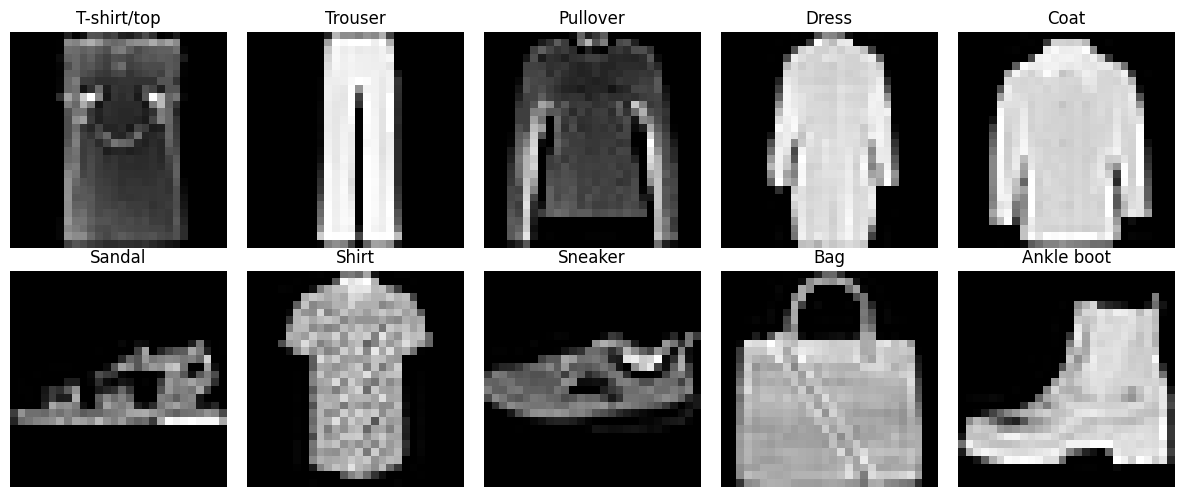

Image size: (28, 28)
Image mode: L


In [ ]:
# Cell 5: Display Sample Images and Verify Image Dimensions
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for label, ax in enumerate(axes.flat):
    sample = train_data[train_data["label"] == label].iloc[0]

    img = Image.open(BytesIO(sample["image"]["bytes"]))

    ax.imshow(img, cmap="gray")
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image size:", img.size)
print("Image mode:", img.mode)

In [ ]:
# Cell 6: Convert Image to Tensor and Normalize Pixel Values

import torch
from torchvision import transforms
from PIL import Image
from io import BytesIO

# Define the transformation
transform = transforms.ToTensor()

# Select a sample image from training data
sample = train_data.iloc[0]
img = Image.open(BytesIO(sample["image"]["bytes"])).convert("L")

# Apply transformation
img_tensor = transform(img)

# Verify the result
print("Tensor shape:", img_tensor.shape)
print("Data type:", img_tensor.dtype)
print("Minimum pixel value:", img_tensor.min().item())
print("Maximum pixel value:", img_tensor.max().item())

Tensor shape: torch.Size([1, 28, 28])
Data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
# Cell 8: Set Random Seeds and Check Computing Device

import random
import numpy as np
import torch

# Set random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configure reproducible CUDA behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Select GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Random Seed:", SEED)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# Cell 7: Create PyTorch Datasets and DataLoaders

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from io import BytesIO

# Define a custom dataset
class FashionDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data.iloc[idx]

        image = Image.open(
            BytesIO(sample["image"]["bytes"])
        ).convert("L")

        label = int(sample["label"])

        if self.transform:
            image = self.transform(image)

        return image, label


# Create datasets
train_dataset = FashionDataset(train_data, transform)
val_dataset = FashionDataset(val_data, transform)
test_dataset = FashionDataset(test_df, transform)

# Create DataLoaders
batch_size = 128

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

# Verify one training batch
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Images shape: torch.Size([128, 1, 28, 28])
Labels shape: torch.Size([128])
Training samples: 54000
Validation samples: 6000
Testing samples: 10000


In [ ]:
# Cell 9: Define the CNN Model Architecture

import torch
import torch.nn as nn
import torch.nn.functional as F

class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()

        # First Convolutional Layer
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)

        # Second Convolutional Layer
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Max Pooling Layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully Connected Layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Create the model and move it to GPU
model = FashionCNN().to(device)

# Display model architecture
print(model)

# Verify output dimensions
with torch.no_grad():
    sample_input = torch.zeros(1, 1, 28, 28).to(device)
    sample_output = model(sample_input)

print("\nOutput shape:", sample_output.shape)

FashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Output shape: torch.Size([1, 10])


In [ ]:
# Cell 10: Configure CNN Training Parameters

import torch.optim as optim

# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer
learning_rate = 0.001
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Set training parameters
num_epochs = 10

# Display configuration
print("Loss Function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning Rate:", learning_rate)
print("Batch Size:", batch_size)
print("Number of Epochs:", num_epochs)
print("Device:", device)

Loss Function: CrossEntropyLoss()
Optimizer: Adam
Learning Rate: 0.001
Batch Size: 128
Number of Epochs: 10
Device: cuda


In [ ]:
# Cell 11: Define CNN Training Function Without Automatic Execution

import os
import time
import torch

def train_cnn(model, train_loader, val_loader,
              criterion, optimizer, num_epochs,
              device, save_path):

    # Prevent accidental overwriting of a saved model
    if os.path.exists(save_path):
        raise FileExistsError(
            "Model file already exists. Use a new save path."
        )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1.0
    start_time = time.time()

    for epoch in range(num_epochs):

        # Training phase
        model.train()
        train_loss = 0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(labels)
            train_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            train_total += len(labels)

        # Validation phase
        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * len(labels)
                val_correct += (
                    outputs.argmax(1) == labels
                ).sum().item()
                val_total += len(labels)

        train_loss /= train_total
        val_loss /= val_total

        train_accuracy = 100 * train_correct / train_total
        val_accuracy = 100 * val_correct / val_total

        # Store training history
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        # Save the best model
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            torch.save(model.state_dict(), save_path)

        print(
            f"Epoch [{epoch+1}/{num_epochs}] | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    training_time = time.time() - start_time

    return history, best_val_accuracy, training_time


# Do not execute training automatically
RUN_TRAINING = False

print("Training function ready.")
print("Training enabled:", RUN_TRAINING)
print("No retraining performed.")

Training function ready.
Training enabled: False
No retraining performed.


In [ ]:
# Cell 11A: Restore Saved CNN Model Without Retraining

import os
import torch

model_path = os.path.join(dataset_path, "best_fashion_cnn.pth")

assert os.path.exists(model_path), "Saved model not found!"

best_model = FashionCNN().to(device)

best_model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)

best_model.eval()

print("Saved CNN model loaded successfully!")
print("Device:", device)
print("No retraining performed.")

In [ ]:
# Cell 12: Evaluate Loaded CNN and Verify Baseline Results

import numpy as np
import pandas as pd
import os
import torch

# Use the trained model loaded in Cell 11A
best_model.eval()

true_labels = []
pred_labels = []

# Evaluate original test images without training
with torch.inference_mode():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        true_labels.extend(labels.tolist())
        pred_labels.extend(predictions.cpu().tolist())

true_labels = np.array(true_labels)
pred_labels = np.array(pred_labels)

# Calculate overall baseline accuracy
baseline_accuracy = (
    (true_labels == pred_labels).mean() * 100
)

print(f"Baseline Test Accuracy: {baseline_accuracy:.2f}%")

# Calculate accuracy for each clothing class
print("\nPer-Class Accuracy:")

for i, class_name in enumerate(classes):

    mask = (true_labels == i)

    class_accuracy = (
        (pred_labels[mask] == true_labels[mask]).mean() * 100
    )

    print(f"{class_name}: {class_accuracy:.2f}%")

# Prepare baseline results
results_dir = os.path.join(dataset_path, "results")
os.makedirs(results_dir, exist_ok=True)

baseline_df = pd.DataFrame({
    "image_index": np.arange(len(true_labels)),
    "true_label": true_labels,
    "original_prediction": pred_labels
})

baseline_csv = os.path.join(
    results_dir, "baseline_predictions.csv"
)

# Verify previous results before saving anything
if os.path.exists(baseline_csv):

    previous = pd.read_csv(baseline_csv)

    assert previous.equals(baseline_df), (
        "Baseline predictions differ from saved results!"
    )

    print("\nPrevious baseline results verified unchanged.")

else:
    baseline_df.to_csv(baseline_csv, index=False)
    print("\nBaseline results saved.")

print("No retraining performed.")

Baseline Test Accuracy: 91.91%

Per-Class Accuracy:
T-shirt/top: 88.90%
Trouser: 98.70%
Pullover: 90.80%
Dress: 91.10%
Coat: 85.40%
Sandal: 97.30%
Shirt: 74.40%
Sneaker: 97.90%
Bag: 98.30%
Ankle boot: 96.30%

Previous baseline results verified unchanged.
No retraining performed.


In [ ]:
# Cell 12B: Load and Display Saved Training History

import pandas as pd
import os

# Load previously saved training results
history_path = os.path.join(
    dataset_path, "results", "training_history.csv"
)

history_df = pd.read_csv(history_path)

# Display all 10 epochs
print("Saved Training History:")
display(history_df.round(4))

print("\nTotal Epochs:", len(history_df))
print(
    "Best Validation Accuracy:",
    f"{history_df['val_accuracy'].max():.2f}%"
)

print("No retraining performed.")

Saved Training History:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.5405,80.6815,0.3484,87.8500
1,2,0.3314,88.1778,0.2719,90.1667
2,3,0.2859,89.5759,0.2617,90.3833
3,4,0.2560,90.7463,0.2382,91.2167
4,5,0.2297,91.5944,0.2639,89.8667
5,6,0.2107,92.3148,0.2143,92.0667
6,7,0.1958,92.7981,0.2275,91.4833
7,8,0.1774,93.5333,0.2104,92.3333
8,9,0.1640,93.8815,0.2010,92.8000
9,10,0.1500,94.6056,0.1942,92.9500



Total Epochs: 10
Best Validation Accuracy: 92.95%
No retraining performed.


In [ ]:
# Cell 13: Define Final Foreground-Aware Occlusion Function

import torch

# Define occlusion mask sizes
occlusion_sizes = {
    "Small": 4,
    "Medium": 8,
    "Large": 12
}

# Define occlusion positions
occlusion_positions = {
    "Top": 0.2,
    "Center": 0.5,
    "Bottom": 0.8
}

# Define foreground threshold
foreground_threshold = 0.1


def apply_occlusion(image, position, size):

    # Preserve the original image
    occluded = image.clone()

    # Identify foreground pixels
    foreground = image[0] > foreground_threshold
    ys, xs = torch.where(foreground)

    if len(xs) == 0:
        raise ValueError("No foreground pixels detected.")

    # Find foreground boundaries
    y_min, y_max = ys.min().item(), ys.max().item()
    x_min, x_max = xs.min().item(), xs.max().item()

    # Determine target position
    target_y = y_min + occlusion_positions[position] * (y_max - y_min)
    target_x = (x_min + x_max) / 2

    # Find nearest foreground pixels
    y_distance = torch.abs(ys.float() - target_y)
    candidates = torch.where(y_distance == y_distance.min())[0]

    # Select foreground pixel closest to horizontal center
    x_distance = torch.abs(xs[candidates].float() - target_x)
    selected = candidates[torch.argmin(x_distance)]

    center_y = ys[selected].item()
    center_x = xs[selected].item()

    # Keep mask within image boundaries
    height, width = image.shape[1:]

    x_start = max(0, min(center_x - size // 2, width - size))
    y_start = max(0, min(center_y - size // 2, height - size))

    # Calculate hidden foreground percentage
    hidden_pixels = foreground[
        y_start:y_start + size,
        x_start:x_start + size
    ].sum().item()

    total_foreground = foreground.sum().item()

    percentage = 100 * hidden_pixels / total_foreground

    # Apply black occlusion mask
    occluded[
        :,
        y_start:y_start + size,
        x_start:x_start + size
    ] = 0.0

    return occluded, percentage


print("Final Foreground-Aware Occlusion Function Ready!")

Final Foreground-Aware Occlusion Function Ready!


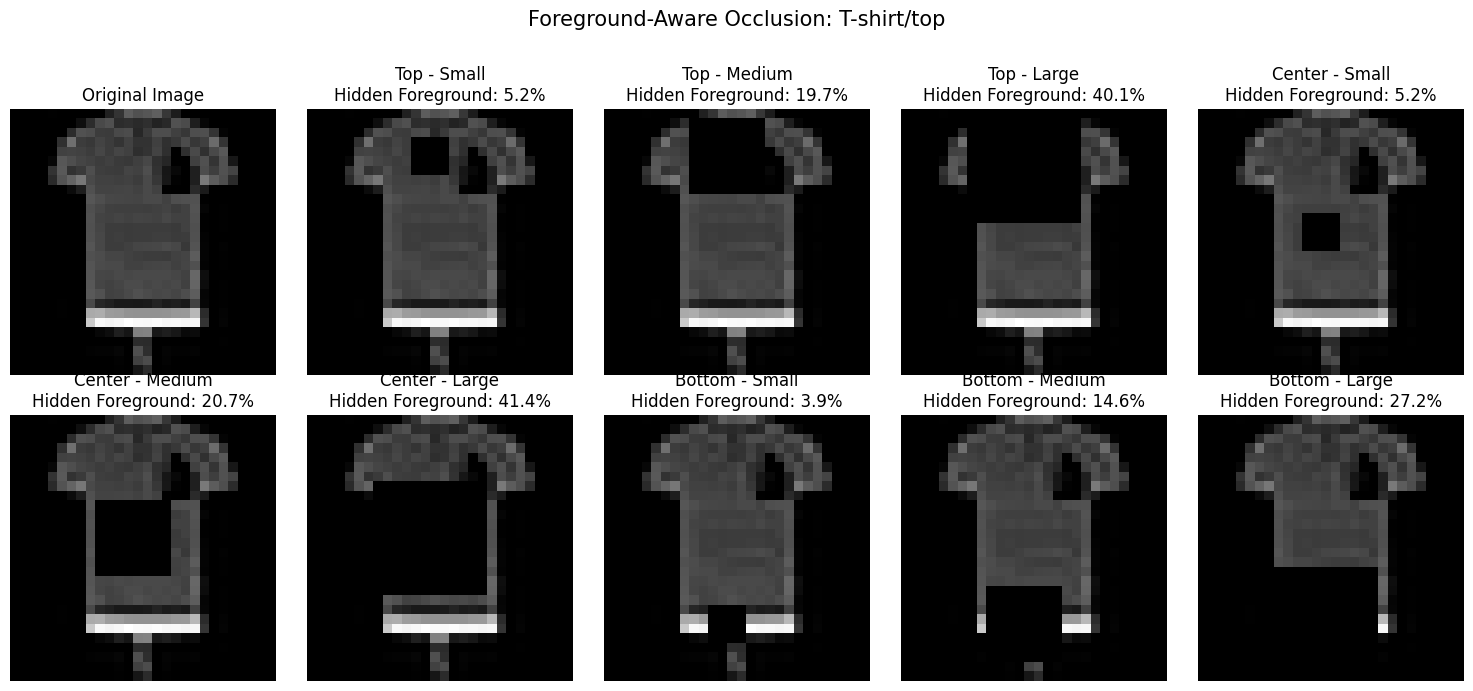

Original image unchanged: True
Occlusion conditions tested: 9


In [ ]:
# Cell 14: Visualize Original Image and 9 Occlusion Conditions

import matplotlib.pyplot as plt
import torch

# Select a T-shirt image from the Validation Dataset
# Use positional indexing to avoid index mismatch
sample_idx = int(
    (val_data["label"] == 0).to_numpy().nonzero()[0][0]
)

image, label = val_dataset[sample_idx]

# Verify that the selected image is a T-shirt
assert int(label) == 0, "Selected image is not a T-shirt."

# Keep a copy to verify the original is unchanged
original_image = image.clone()

# Create a figure with 10 images
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

# Display the original image
axes[0].imshow(
    image.squeeze(),
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0].set_title("Original Image")
axes[0].axis("off")

# Apply all 9 occlusion combinations
idx = 1

for position in occlusion_positions:
    for size_name, size_value in occlusion_sizes.items():

        occluded, percentage = apply_occlusion(
            image, position, size_value
        )

        # Verify output validity
        assert occluded.shape == image.shape
        assert 0 <= percentage <= 100

        axes[idx].imshow(
            occluded.squeeze(),
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[idx].set_title(
            f"{position} - {size_name}\n"
            f"Hidden Foreground: {percentage:.1f}%"
        )

        axes[idx].axis("off")
        idx += 1

plt.suptitle(
    f"Foreground-Aware Occlusion: {classes[label]}",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=3.0)
plt.show()

# Verify that occlusion did not modify the original image
print(
    "Original image unchanged:",
    torch.equal(image, original_image)
)

print("Occlusion conditions tested:", idx - 1)

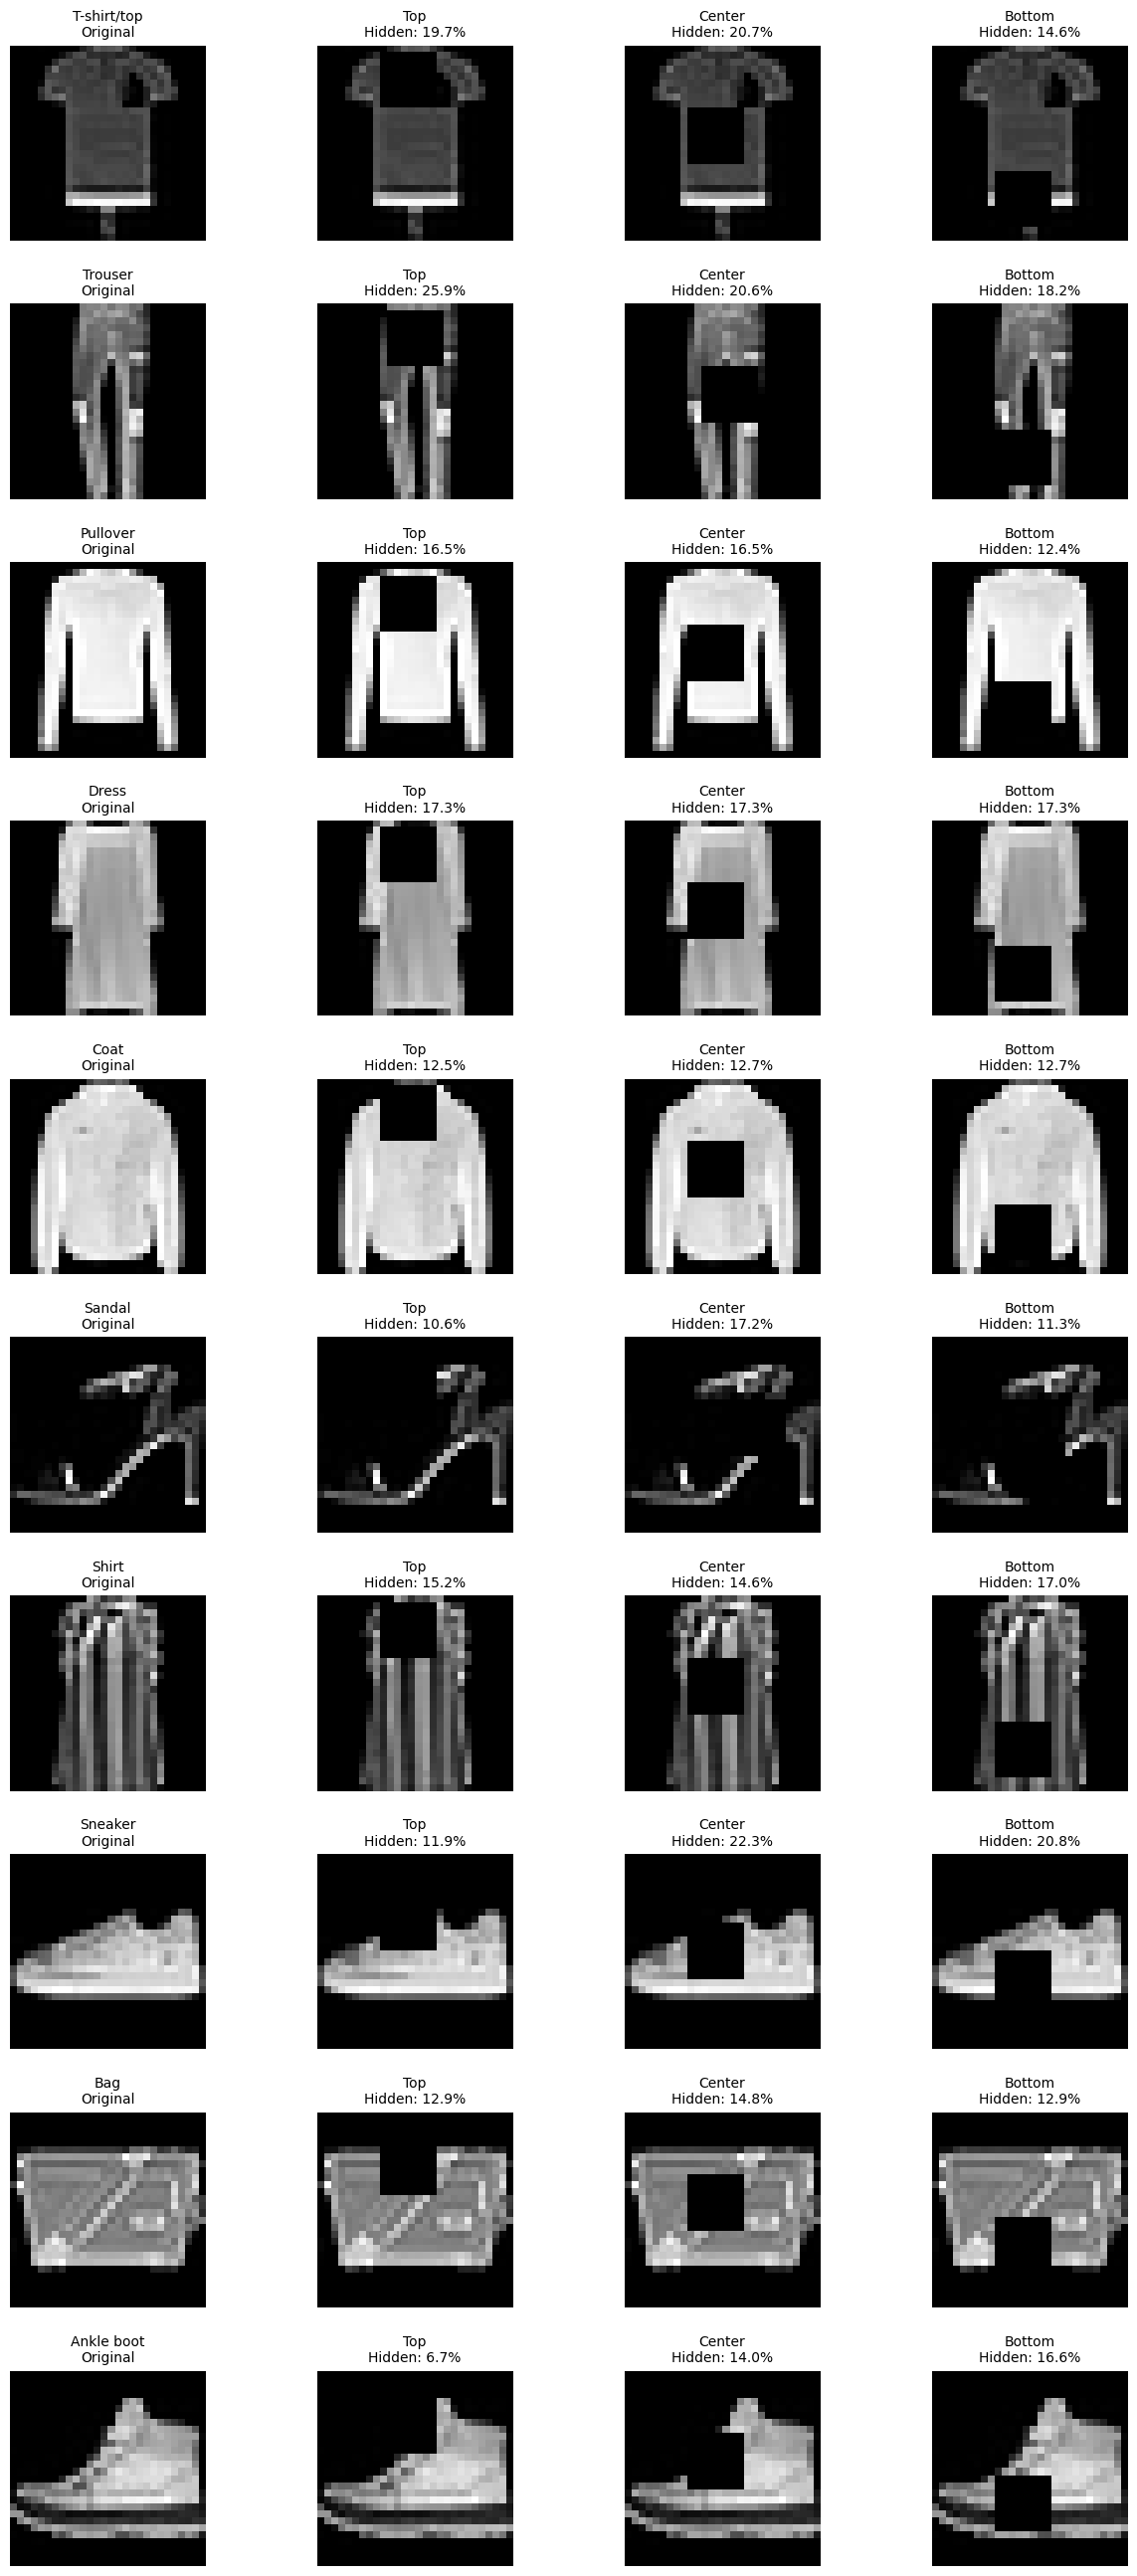

Classes checked: 10
Occlusion cases verified: 90
No retraining performed.


In [ ]:
# Cell 15: Validate Occlusion Across All 10 Clothing Classes

import matplotlib.pyplot as plt
import torch

# Create a figure for all clothing classes
fig, axes = plt.subplots(10, 4, figsize=(13, 26))

verified_cases = 0

for class_idx, class_name in enumerate(classes):

    # Select one validation image from each class
    # Use positional indexing to avoid index mismatch
    sample_idx = int(
        (val_data["label"] == class_idx)
        .to_numpy()
        .nonzero()[0][0]
    )

    image, label = val_dataset[sample_idx]

    # Verify the selected image belongs to the correct class
    assert int(label) == class_idx, (
        f"Incorrect image selected for {class_name}"
    )

    original_image = image.clone()

    # Display original image
    axes[class_idx, 0].imshow(
        image.squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[class_idx, 0].set_title(
        f"{class_name}\nOriginal",
        fontsize=10
    )

    axes[class_idx, 0].axis("off")

    # Display Medium occlusion at three positions
    for col, position in enumerate(
        ["Top", "Center", "Bottom"], start=1
    ):

        occluded, percentage = apply_occlusion(
            image,
            position,
            occlusion_sizes["Medium"]
        )

        axes[class_idx, col].imshow(
            occluded.squeeze(),
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[class_idx, col].set_title(
            f"{position}\nHidden: {percentage:.1f}%",
            fontsize=10
        )

        axes[class_idx, col].axis("off")

    # Verify all nine occlusion settings for this class
    for position in occlusion_positions:
        for size in occlusion_sizes.values():

            occluded, percentage = apply_occlusion(
                image, position, size
            )

            assert occluded.shape == image.shape
            assert 0 <= percentage <= 100
            assert torch.equal(image, original_image)

            verified_cases += 1

plt.tight_layout(h_pad=2.0)
plt.show()

print("Classes checked:", len(classes))
print("Occlusion cases verified:", verified_cases)
print("No retraining performed.")

In [ ]:
# Cell 17: Consolidate Occlusion Evaluation and Results

import os
import numpy as np
import pandas as pd
import torch

results_dir = os.path.join(dataset_path, "results")
os.makedirs(results_dir, exist_ok=True)

detail_path = os.path.join(
    results_dir, "per_image_occlusion_results.csv"
)
summary_path = os.path.join(
    results_dir, "occlusion_summary.csv"
)
classwise_path = os.path.join(
    results_dir, "occlusion_classwise.csv"
)

# Load existing detailed results if available
if os.path.exists(detail_path):
    detailed_df = pd.read_csv(detail_path)
    print("Loaded existing per-image results.")

else:
    # Restore the trained model without retraining
    if "FashionCNN" not in globals():
        raise RuntimeError(
            "Run Cell 9 to define FashionCNN. Do not run Cell 11."
        )

    eval_model = FashionCNN().to(device)
    eval_model.load_state_dict(
        torch.load(
            os.path.join(dataset_path, "best_fashion_cnn.pth"),
            map_location=device,
            weights_only=True
        )
    )
    eval_model.eval()

    baseline_data = pd.read_csv(
        os.path.join(results_dir, "baseline_predictions.csv")
    ).sort_values("image_index").reset_index(drop=True)

    records = []

    # Evaluate every occlusion position and size
    with torch.inference_mode():
        for position in occlusion_positions:
            for size_name, size_value in occlusion_sizes.items():

                image_index = 0

                for images, labels in test_loader:
                    masked_images = []
                    percentages = []

                    for image in images:
                        masked, pct = apply_occlusion(
                            image, position, size_value
                        )
                        masked_images.append(masked)
                        percentages.append(pct)

                    predictions = eval_model(
                        torch.stack(masked_images).to(device)
                    ).argmax(1).cpu().tolist()

                    for i, true_label in enumerate(labels.tolist()):
                        original = baseline_data.iloc[image_index]

                        assert int(original["true_label"]) == true_label

                        records.append({
                            "image_index": image_index,
                            "class": classes[true_label],
                            "position": position,
                            "size": size_name,
                            "hidden_foreground_pct": percentages[i],
                            "original_correct": int(
                                original["original_prediction"] == true_label
                            ),
                            "occluded_correct": int(
                                predictions[i] == true_label
                            ),
                            "occluded_prediction": predictions[i]
                        })

                        image_index += 1

                print(f"Evaluated: {position} - {size_name}")

    detailed_df = pd.DataFrame(records)
    detailed_df.to_csv(detail_path, index=False)

# Verify completeness of the detailed results
assert len(detailed_df) == 90000
assert not detailed_df.duplicated(
    ["image_index", "position", "size"]
).any()
assert detailed_df.groupby("image_index").size().eq(9).all()

# Calculate the original test accuracy
baseline_accuracy = (
    detailed_df.drop_duplicates("image_index")[
        "original_correct"
    ].mean() * 100
)

# Create overall occlusion summary
occlusion_summary_df = detailed_df.groupby(
    ["position", "size"], as_index=False
).agg(
    overall_accuracy=("occluded_correct", "mean"),
    mean_hidden_foreground_pct=("hidden_foreground_pct", "mean")
)

occlusion_summary_df["overall_accuracy"] *= 100
occlusion_summary_df["accuracy_drop"] = (
    baseline_accuracy - occlusion_summary_df["overall_accuracy"]
)

occlusion_summary_df = occlusion_summary_df[
    ["position", "size", "overall_accuracy",
     "accuracy_drop", "mean_hidden_foreground_pct"]
]

# Create class-wise summary
classwise_summary_df = detailed_df.groupby(
    ["position", "size", "class"], as_index=False
).agg(
    class_accuracy=("occluded_correct", "mean"),
    baseline_class_accuracy=("original_correct", "mean")
)

classwise_summary_df["class_accuracy_drop"] = (
    classwise_summary_df["baseline_class_accuracy"]
    - classwise_summary_df["class_accuracy"]
) * 100

classwise_summary_df["class_accuracy"] *= 100

classwise_summary_df = classwise_summary_df[
    ["position", "size", "class",
     "class_accuracy", "class_accuracy_drop"]
]

# Compare recomputed results with existing saved results
def verify_existing_results(new_df, path, keys, metrics):
    if os.path.exists(path):
        previous = pd.read_csv(path)

        check = new_df.merge(
            previous,
            on=keys,
            suffixes=("_new", "_old"),
            validate="one_to_one"
        )

        assert len(check) == len(new_df) == len(previous)

        for metric in metrics:
            assert np.allclose(
                check[f"{metric}_new"],
                check[f"{metric}_old"],
                atol=1e-6,
                rtol=0
            ), f"Results changed: {metric}"

        print(f"Verified unchanged: {os.path.basename(path)}")

verify_existing_results(
    occlusion_summary_df,
    summary_path,
    ["position", "size"],
    ["overall_accuracy", "accuracy_drop",
     "mean_hidden_foreground_pct"]
)

verify_existing_results(
    classwise_summary_df,
    classwise_path,
    ["position", "size", "class"],
    ["class_accuracy", "class_accuracy_drop"]
)

# Save verified results
occlusion_summary_df.to_csv(summary_path, index=False)
classwise_summary_df.to_csv(classwise_path, index=False)

print("\nBaseline Accuracy:", round(baseline_accuracy, 2), "%")
print("Overall conditions:", len(occlusion_summary_df))
print("Class-wise results:", len(classwise_summary_df))
print("Per-image records:", len(detailed_df))
print("All results consolidated successfully!")

Loaded existing per-image results.
Verified unchanged: occlusion_summary.csv
Verified unchanged: occlusion_classwise.csv

Baseline Accuracy: 91.91 %
Overall conditions: 9
Class-wise results: 90
Per-image records: 90000
All results consolidated successfully!


In [ ]:
# Cell 16: Verify Saved Occlusion Results Before Cleanup

import os
import pandas as pd

results_path = os.path.join(dataset_path, "results")

files = {
    "Occlusion Summary": ("occlusion_summary.csv", 9),
    "Class-Wise Results": ("occlusion_classwise.csv", 90),
    "Per-Image Results": ("per_image_occlusion_results.csv", 90000)
}

for name, (filename, expected_rows) in files.items():

    path = os.path.join(results_path, filename)

    assert os.path.exists(path), f"Missing file: {filename}"

    data = pd.read_csv(path)

    assert len(data) == expected_rows, (
        f"Unexpected number of rows in {filename}"
    )

    print(f"{name}: {len(data)} rows - Saved correctly")

print("\nAll occlusion result files are available!")

In [ ]:
# Cell 18: Analyze Class-Wise Accuracy Drop

import pandas as pd
import os
from IPython.display import display

# Load saved class-wise occlusion results
classwise_path = os.path.join(
    dataset_path, "results", "occlusion_classwise.csv"
)

classwise_results = pd.read_csv(classwise_path)

# Create a label for each occlusion condition
classwise_results["condition"] = (
    classwise_results["position"] + " - " +
    classwise_results["size"]
)

# Define the order of the nine conditions
conditions = [
    f"{position} - {size}"
    for position in ["Top", "Center", "Bottom"]
    for size in ["Small", "Medium", "Large"]
]

# Compare accuracy drops across the 10 classes
classwise_table = classwise_results.pivot(
    index="class",
    columns="condition",
    values="class_accuracy_drop"
)

# Organize rows and columns
classwise_table = classwise_table.reindex(
    index=classes,
    columns=conditions
)

print("Class-Wise Accuracy Drop (percentage points):")
display(classwise_table.round(2))

print("\nNumber of clothing classes:", len(classwise_table))
print("Number of occlusion conditions:", len(conditions))

Class-Wise Accuracy Drop (percentage points):


condition,Top - Small,Top - Medium,Top - Large,Center - Small,Center - Medium,Center - Large,Bottom - Small,Bottom - Medium,Bottom - Large
class,,,,,,,,,
T-shirt/top,6.6,4.1,2.1,-3.6,-2.8,-3.3,22.1,17.5,13.9
Trouser,0.1,3.9,10.9,0.3,1.5,2.9,0.3,0.9,59.9
Pullover,4.4,3.5,3.3,-5.2,-5.2,-1.8,8.8,10.0,-0.2
Dress,1.9,3.8,22.9,9.3,21.0,31.0,17.9,46.9,39.2
Coat,19.4,82.2,77.8,65.4,70.5,65.8,-0.1,20.4,25.4
Sandal,0.2,-1.4,-2.5,-2.6,-2.7,-2.2,-0.9,-2.3,-2.0
Shirt,-6.5,14.6,44.5,20.3,26.8,43.7,-3.0,-2.2,15.8
Sneaker,0.0,13.8,79.8,7.8,64.2,94.9,-0.6,36.4,88.8
Bag,-0.4,0.1,3.0,0.1,0.5,0.5,-0.4,0.6,2.2



Number of clothing classes: 10
Number of occlusion conditions: 9


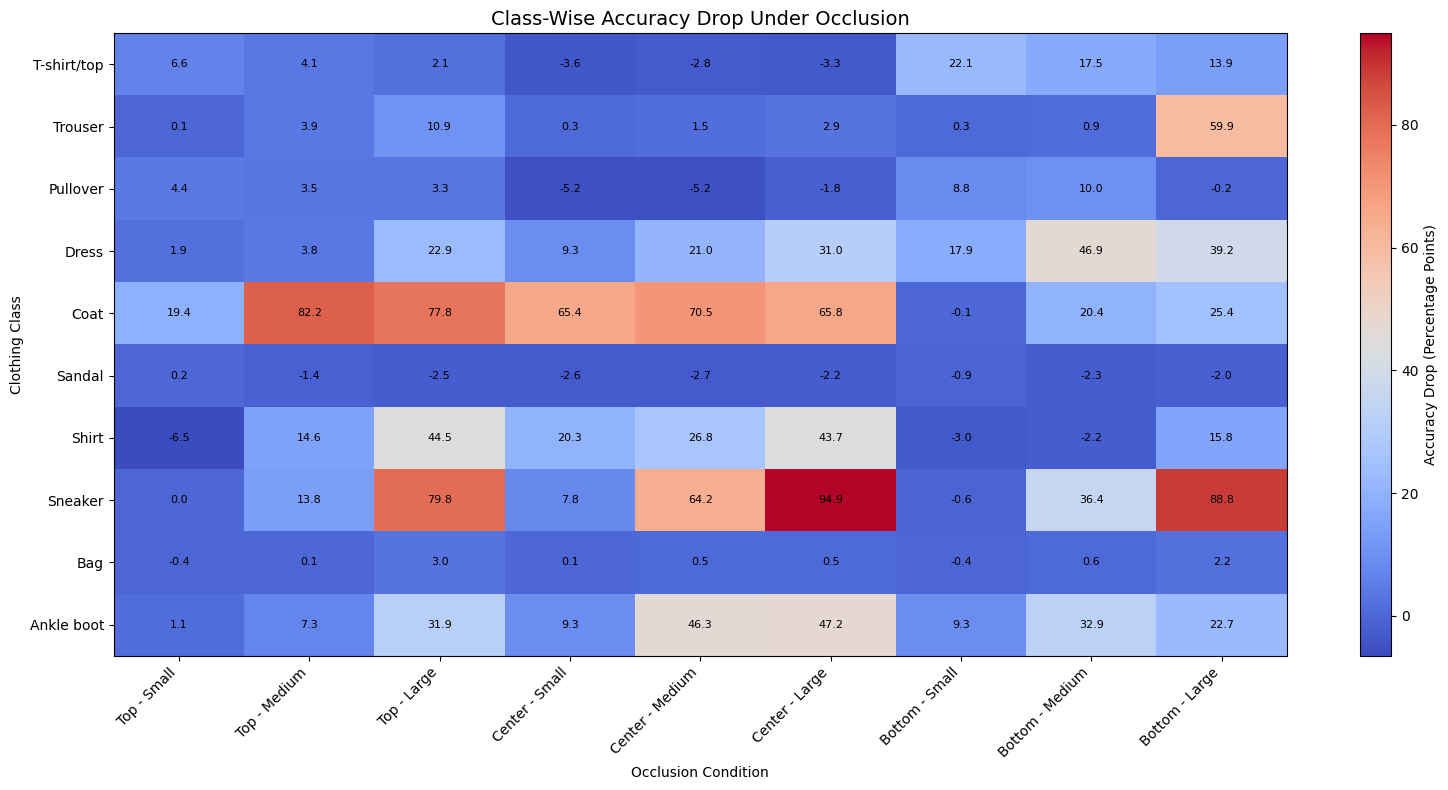

Heatmap saved to: /content/drive/MyDrive/DLproject1/results/classwise_heatmap.png


In [ ]:
# Cell 19: Visualize Class-Wise Accuracy Drop Using Heatmap

import matplotlib.pyplot as plt
import numpy as np
import os

# Prepare class-wise accuracy drop values
heatmap_data = classwise_table.values

# Create the heatmap
fig, ax = plt.subplots(figsize=(16, 8))

im = ax.imshow(
    heatmap_data,
    cmap="coolwarm",
    aspect="auto"
)

# Set axis labels
ax.set_xticks(range(len(conditions)))
ax.set_xticklabels(conditions, rotation=45, ha="right")

ax.set_yticks(range(len(classes)))
ax.set_yticklabels(classes)

# Add values inside each cell
for i in range(len(classes)):
    for j in range(len(conditions)):
        ax.text(
            j, i,
            f"{heatmap_data[i, j]:.1f}",
            ha="center",
            va="center",
            fontsize=8
        )

# Add title and colorbar
ax.set_title(
    "Class-Wise Accuracy Drop Under Occlusion",
    fontsize=14
)

ax.set_xlabel("Occlusion Condition")
ax.set_ylabel("Clothing Class")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Accuracy Drop (Percentage Points)")

plt.tight_layout()

# Save the figure
heatmap_path = os.path.join(
    dataset_path,
    "results",
    "classwise_heatmap.png"
)

plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

print("Heatmap saved to:", heatmap_path)

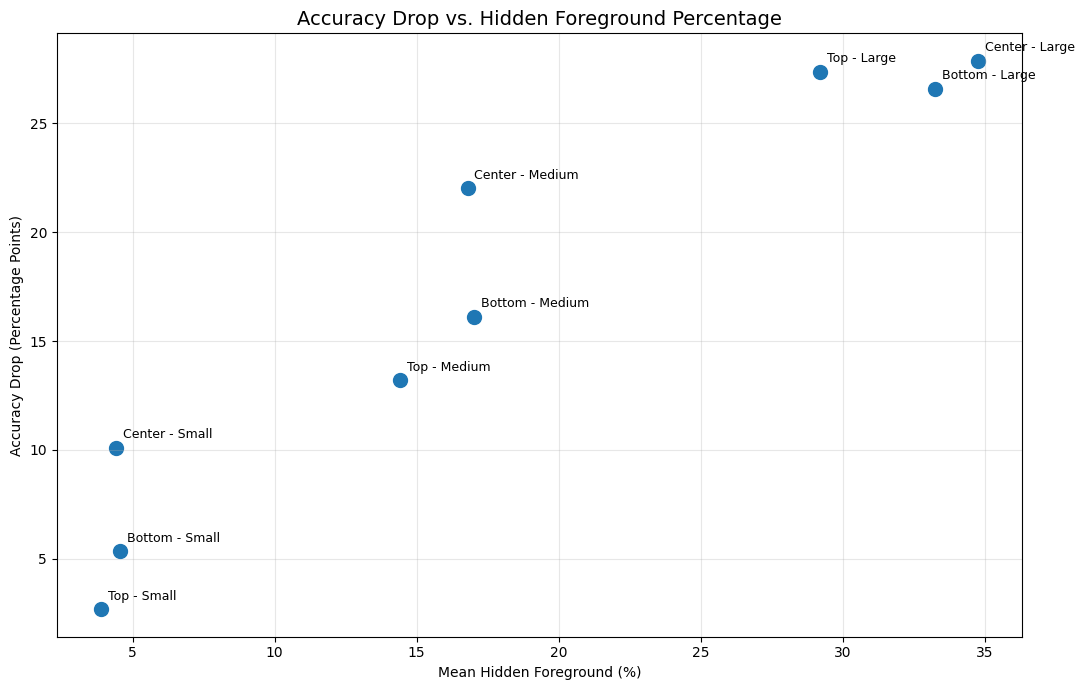

Figure saved to: /content/drive/MyDrive/DLproject1/results/foreground_vs_accuracy_drop.png


In [ ]:
# Cell 20: Analyze Accuracy Drop vs. Hidden Foreground Percentage

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load saved occlusion results
results_path = os.path.join(
    dataset_path, "results", "occlusion_summary.csv"
)

results = pd.read_csv(results_path)

# Create the scatter plot
plt.figure(figsize=(11, 7))

plt.scatter(
    results["mean_hidden_foreground_pct"],
    results["accuracy_drop"],
    s=100
)

# Label each occlusion condition
for _, row in results.iterrows():

    label = f"{row['position']} - {row['size']}"

    plt.annotate(
        label,
        (
            row["mean_hidden_foreground_pct"],
            row["accuracy_drop"]
        ),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9
    )

# Add titles and labels
plt.title(
    "Accuracy Drop vs. Hidden Foreground Percentage",
    fontsize=14
)

plt.xlabel("Mean Hidden Foreground (%)")
plt.ylabel("Accuracy Drop (Percentage Points)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the figure
figure_path = os.path.join(
    dataset_path,
    "results",
    "foreground_vs_accuracy_drop.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)

In [ ]:
# Cell 22: Validate Per-Image Occlusion Results

import pandas as pd
import os

# Load detailed results
detailed_path = os.path.join(
    dataset_path, "results", "per_image_occlusion_results.csv"
)

df = pd.read_csv(detailed_path)

# Verify dataset completeness
assert len(df) == 90000
assert not df.isnull().any().any()

# Verify no duplicate experiments
assert not df.duplicated(
    ["image_index", "position", "size"]
).any()

# Verify each image has 9 conditions
assert df.groupby("image_index").size().eq(9).all()

# Verify valid foreground percentages
assert df["hidden_foreground_pct"].between(0, 100).all()

# Calculate summary statistics
audit = df.groupby(
    ["position", "size"], as_index=False
).agg(
    images=("image_index", "count"),
    mean_hidden=("hidden_foreground_pct", "mean"),
    median_hidden=("hidden_foreground_pct", "median"),
    min_hidden=("hidden_foreground_pct", "min"),
    accuracy=("occluded_correct", "mean")
)

# Convert accuracy to percentage
audit["accuracy"] *= 100

print("Total records:", len(df))
print("Duplicate records: 0")
print("All images have 9 conditions: True")

print("\nOcclusion Quality Report:")
display(audit.round(2))

# Check masks that cover no foreground pixels
zero_masks = (df["hidden_foreground_pct"] == 0).sum()

print("\nZero-foreground occlusions:", zero_masks)

Total records: 90000
Duplicate records: 0
All images have 9 conditions: True

Occlusion Quality Report:


,position,size,images,mean_hidden,median_hidden,min_hidden,accuracy
0,Bottom,Large,10000,33.27,32.71,10.71,65.34
1,Bottom,Medium,10000,17.01,15.80,4.02,75.80
2,Bottom,Small,10000,4.57,4.12,0.57,86.57
3,Center,Large,10000,34.76,33.25,6.31,64.04
4,Center,Medium,10000,16.79,15.11,3.90,69.90
5,Center,Small,10000,4.40,3.86,0.35,81.80
6,Top,Large,10000,29.20,28.54,1.77,64.54
7,Top,Medium,10000,14.43,13.58,1.77,78.72
8,Top,Small,10000,3.88,3.53,0.40,89.23



Zero-foreground occlusions: 0


In [ ]:
# Cell 23: Compare Occlusion Positions at Similar Foreground Coverage

import pandas as pd
import os

# Use the saved per-image evaluation results
df = pd.read_csv(
    os.path.join(
        dataset_path,
        "results",
        "per_image_occlusion_results.csv"
    )
)

# Define a fixed coverage tolerance
tolerance = 3.0

positions = ["Top", "Center", "Bottom"]
sizes = ["Small", "Medium", "Large"]

# Organize results for the same image and mask size
paired = df.pivot(
    index=["image_index", "class", "size"],
    columns="position",
    values=[
        "hidden_foreground_pct",
        "occluded_correct",
        "original_correct"
    ]
)

# Extract foreground coverage and classification outcomes
coverage = paired["hidden_foreground_pct"][positions]
correct = paired["occluded_correct"][positions]
original = paired["original_correct"]["Top"]

# Calculate coverage difference among the three positions
coverage_difference = (
    coverage.max(axis=1) - coverage.min(axis=1)
)

matched = coverage_difference <= tolerance

comparison_results = []

# Compare positions separately for each mask size
for size in sizes:

    size_mask = coverage.index.get_level_values("size") == size
    selected = size_mask & matched

    n = int(selected.sum())

    if n == 0:
        print(f"{size}: No comparable images found.")
        continue

    baseline_acc = original[selected].mean() * 100

    for position in positions:

        position_acc = correct.loc[
            selected, position
        ].mean() * 100

        comparison_results.append({
            "size": size,
            "position": position,
            "matched_images": n,
            "baseline_accuracy": baseline_acc,
            "occluded_accuracy": position_acc,
            "accuracy_drop": baseline_acc - position_acc
        })

    print(f"{size}: {n} comparable images out of 10000")

# Display comparison results
matched_df = pd.DataFrame(comparison_results)

print("\nMatched Position Comparison:")
display(matched_df.round(2))

# Check the number of matched images in each class
matched_counts = coverage.index.to_frame(index=False)
matched_counts["matched"] = matched.to_numpy()

class_counts = matched_counts.groupby(
    ["size", "class"]
)["matched"].sum().unstack(fill_value=0)

print("\nComparable Images by Clothing Class:")
display(class_counts.reindex(sizes))

# Save results
save_path = os.path.join(
    dataset_path,
    "results",
    "matched_position_comparison.csv"
)

matched_df.to_csv(save_path, index=False)

print("\nResults saved to:", save_path)

Small: 8507 comparable images out of 10000
Medium: 4606 comparable images out of 10000
Large: 2116 comparable images out of 10000

Matched Position Comparison:


,size,position,matched_images,baseline_accuracy,occluded_accuracy,accuracy_drop
0,Small,Top,8507,91.14,87.96,3.17
1,Small,Center,8507,91.14,79.95,11.19
2,Small,Bottom,8507,91.14,85.33,5.81
3,Medium,Top,4606,87.52,67.93,19.58
4,Medium,Center,4606,87.52,67.30,20.21
5,Medium,Bottom,4606,87.52,70.08,17.43
6,Large,Top,2116,87.15,62.38,24.76
7,Large,Center,2116,87.15,66.40,20.75
8,Large,Bottom,2116,87.15,69.19,17.96



Comparable Images by Clothing Class:


class,Ankle boot,Bag,Coat,Dress,Pullover,Sandal,Shirt,Sneaker,T-shirt/top,Trouser
size,,,,,,,,,,
Small,760,904,996,992,996,593,995,382,982,907
Medium,15,335,822,751,811,39,855,1,878,99
Large,2,48,227,291,329,63,467,7,660,22



Results saved to: /content/drive/MyDrive/DLproject1/results/matched_position_comparison.csv


In [ ]:
# Cell 24: Analyze Matched Occlusion Results by Clothing Class

import pandas as pd
import numpy as np
import os
from IPython.display import display

# Load saved per-image results
df = pd.read_csv(
    os.path.join(
        dataset_path, "results",
        "per_image_occlusion_results.csv"
    )
)

positions = ["Top", "Center", "Bottom"]
sizes = ["Small", "Medium", "Large"]

# Organize results by image, class, and size
wide = df.pivot(
    index=["image_index", "class", "size"],
    columns="position",
    values=["hidden_foreground_pct", "occluded_correct"]
)

coverage = wide["hidden_foreground_pct"][positions]
correct = wide["occluded_correct"][positions]

# Keep images with similar foreground coverage
tolerance = 3.0

matched = (
    coverage.max(axis=1) - coverage.min(axis=1)
) <= tolerance

results = []

# Analyze each clothing class separately
for size in sizes:
    for class_name in classes:

        selected = (
            matched
            & (coverage.index.get_level_values("size") == size)
            & (coverage.index.get_level_values("class") == class_name)
        )

        n = int(selected.sum())

        if n > 0:
            accuracy = correct.loc[
                selected, positions
            ].mean() * 100
        else:
            accuracy = pd.Series(np.nan, index=positions)

        results.append({
            "Size": size,
            "Class": class_name,
            "Matched Images": n,
            "Top Accuracy": accuracy["Top"],
            "Center Accuracy": accuracy["Center"],
            "Bottom Accuracy": accuracy["Bottom"],
            "Center Extra Drop vs Top": (
                accuracy["Top"] - accuracy["Center"]
            ),
            "Sample Status": (
                "Limited" if n < 100 else "Exploratory"
            )
        })

# Create results table
class_matched_df = pd.DataFrame(results)

# Display a separate table for each mask size
for size in sizes:
    print(f"\n{size} Occlusion - Class-Wise Comparison")

    display(
        class_matched_df[
            class_matched_df["Size"] == size
        ].round(2)
    )

# Save results to Google Drive
save_path = os.path.join(
    dataset_path,
    "results",
    "classwise_matched_comparison.csv"
)

class_matched_df.to_csv(save_path, index=False)

print("\nResults saved to:", save_path)


Small Occlusion - Class-Wise Comparison


,Size,Class,Matched Images,Top Accuracy,Center Accuracy,Bottom Accuracy,Center Extra Drop vs Top,Sample Status
0,Small,T-shirt/top,982,82.48,92.77,66.90,-10.29,Exploratory
1,Small,Trouser,907,98.57,98.35,98.46,0.22,Exploratory
2,Small,Pullover,996,86.55,96.08,81.93,-9.54,Exploratory
3,Small,Dress,992,89.42,81.85,73.29,7.56,Exploratory
4,Small,Coat,996,66.06,19.88,85.64,46.18,Exploratory
5,Small,Sandal,593,96.96,99.83,97.98,-2.87,Exploratory
6,Small,Shirt,995,80.80,54.07,77.29,26.73,Exploratory
7,Small,Sneaker,382,95.81,87.17,97.91,8.64,Exploratory
8,Small,Bag,904,98.89,98.34,98.78,0.55,Exploratory
9,Small,Ankle boot,760,96.45,89.34,91.58,7.11,Exploratory



Medium Occlusion - Class-Wise Comparison


,Size,Class,Matched Images,Top Accuracy,Center Accuracy,Bottom Accuracy,Center Extra Drop vs Top,Sample Status
10,Medium,T-shirt/top,878,85.65,93.62,72.89,-7.97,Exploratory
11,Medium,Trouser,99,80.81,86.87,91.92,-6.06,Limited
12,Medium,Pullover,811,87.05,95.56,79.16,-8.51,Exploratory
13,Medium,Dress,751,87.22,71.24,39.95,15.98,Exploratory
14,Medium,Coat,822,2.68,11.92,62.29,-9.25,Exploratory
15,Medium,Sandal,39,97.44,100.00,100.00,-2.56,Limited
16,Medium,Shirt,855,62.22,48.30,77.54,13.92,Exploratory
17,Medium,Sneaker,1,0.00,0.00,0.00,0.00,Limited
18,Medium,Bag,335,98.21,98.51,98.21,-0.30,Exploratory
19,Medium,Ankle boot,15,100.00,13.33,80.00,86.67,Limited



Large Occlusion - Class-Wise Comparison


,Size,Class,Matched Images,Top Accuracy,Center Accuracy,Bottom Accuracy,Center Extra Drop vs Top,Sample Status
20,Large,T-shirt/top,660,90.91,96.06,80.00,-5.15,Exploratory
21,Large,Trouser,22,18.18,72.73,4.55,-54.55,Limited
22,Large,Pullover,329,75.08,86.93,92.71,-11.85,Exploratory
23,Large,Dress,291,72.85,65.64,48.45,7.22,Exploratory
24,Large,Coat,227,3.96,13.66,45.81,-9.69,Exploratory
25,Large,Sandal,63,100.00,100.00,98.41,0.00,Limited
26,Large,Shirt,467,31.91,29.76,58.67,2.14,Exploratory
27,Large,Sneaker,7,0.00,0.00,14.29,0.00,Limited
28,Large,Bag,48,72.92,93.75,95.83,-20.83,Limited
29,Large,Ankle boot,2,50.00,0.00,100.00,50.00,Limited



Results saved to: /content/drive/MyDrive/DLproject1/results/classwise_matched_comparison.csv


In [ ]:
# Cell 25: Consolidate Fixed-Center and Foreground-Aware Comparisons

import os
import torch
import numpy as np
import pandas as pd
from IPython.display import display

results_dir = os.path.join(dataset_path, "results")

paired_path = os.path.join(
    results_dir, "fixed_vs_foreground_per_image.csv"
)
summary_path = os.path.join(
    results_dir, "fixed_vs_foreground_comparison.csv"
)
classwise_path = os.path.join(
    results_dir, "classwise_method_comparison.csv"
)
fg_path = os.path.join(
    results_dir, "per_image_occlusion_results.csv"
)

sizes = ["Small", "Medium", "Large"]

# Step 1: Load existing results or reproduce the evaluation
if os.path.exists(paired_path):

    comparison = pd.read_csv(paired_path)
    print("Loaded existing per-image comparison results.")

else:

    # Load saved CNN weights without retraining
    if "FashionCNN" not in globals():
        raise RuntimeError(
            "Run Cell 9 to define CNN, but do not run Cell 11."
        )

    eval_model = FashionCNN().to(device)

    eval_model.load_state_dict(
        torch.load(
            os.path.join(dataset_path, "best_fashion_cnn.pth"),
            map_location=device,
            weights_only=True
        )
    )

    eval_model.eval()

    fixed_records = []

    # Evaluate fixed-center occlusion for each mask size
    with torch.inference_mode():

        for size_name, size_value in occlusion_sizes.items():

            start = (28 - size_value) // 2
            end = start + size_value
            image_index = 0

            for images, labels in test_loader:

                foreground = images[:, 0] > foreground_threshold

                total_fg = foreground.sum(dim=(1, 2))
                hidden_fg = foreground[
                    :, start:end, start:end
                ].sum(dim=(1, 2))

                hidden_pct = (
                    100 * hidden_fg.float() /
                    total_fg.clamp(min=1)
                )

                occluded = images.clone()
                occluded[:, :, start:end, start:end] = 0.0

                predictions = eval_model(
                    occluded.to(device)
                ).argmax(dim=1).cpu().tolist()

                for i, label in enumerate(labels.tolist()):

                    fixed_records.append({
                        "image_index": image_index,
                        "class": classes[label],
                        "size": size_name,
                        "fixed_correct": int(
                            predictions[i] == label
                        ),
                        "fixed_hidden_pct": float(hidden_pct[i]),
                        "fixed_zero_mask": int(hidden_fg[i] == 0)
                    })

                    image_index += 1

            assert image_index == 10000
            print(f"Evaluated Fixed-Center: {size_name}")

    fixed_df = pd.DataFrame(fixed_records)

    # Match the same images with our Foreground-Aware results
    fg_df = pd.read_csv(fg_path)

    fg_center = fg_df[
        fg_df["position"] == "Center"
    ][[
        "image_index", "class", "size",
        "hidden_foreground_pct", "occluded_correct"
    ]].rename(columns={
        "hidden_foreground_pct": "fg_hidden_pct",
        "occluded_correct": "fg_correct"
    })

    comparison = fixed_df.merge(
        fg_center,
        on=["image_index", "class", "size"],
        validate="one_to_one"
    )

# Step 2: Verify detailed comparison data
assert len(comparison) == 30000

assert not comparison.duplicated(
    ["image_index", "size"]
).any()

assert comparison.groupby("size").size().eq(10000).all()

assert not comparison.isnull().any().any()

# Step 3: Calculate overall comparison
summary = comparison.groupby(
    "size", as_index=False
).agg(
    fixed_accuracy=("fixed_correct", "mean"),
    fg_accuracy=("fg_correct", "mean"),
    fixed_hidden=("fixed_hidden_pct", "mean"),
    fg_hidden=("fg_hidden_pct", "mean"),
    fixed_zero_masks=("fixed_zero_mask", "sum")
)

summary["fixed_accuracy"] *= 100
summary["fg_accuracy"] *= 100

overall_comparison = summary.rename(columns={
    "size": "Size",
    "fixed_accuracy": "Fixed Accuracy",
    "fg_accuracy": "Foreground-Aware Accuracy",
    "fixed_hidden": "Fixed Hidden FG (%)",
    "fg_hidden": "Foreground-Aware Hidden FG (%)",
    "fixed_zero_masks": "Fixed Zero-FG Masks"
})

# Step 4: Calculate class-wise comparison
class_comparison = comparison.groupby(
    ["size", "class"], as_index=False
).agg(
    fixed_accuracy=("fixed_correct", "mean"),
    fg_accuracy=("fg_correct", "mean"),
    fixed_hidden=("fixed_hidden_pct", "mean"),
    fg_hidden=("fg_hidden_pct", "mean"),
    fixed_zero_masks=("fixed_zero_mask", "sum")
)

class_comparison["fixed_accuracy"] *= 100
class_comparison["fg_accuracy"] *= 100

class_comparison["accuracy_difference"] = (
    class_comparison["fg_accuracy"]
    - class_comparison["fixed_accuracy"]
)

# Step 5: Verify that saved results remain unchanged
def verify_results(new_df, path, keys, metrics):

    if os.path.exists(path):

        old_df = pd.read_csv(path)

        merged = new_df.merge(
            old_df,
            on=keys,
            suffixes=("_new", "_old"),
            validate="one_to_one"
        )

        assert len(merged) == len(new_df) == len(old_df)

        for metric in metrics:
            assert np.allclose(
                merged[f"{metric}_new"],
                merged[f"{metric}_old"],
                atol=1e-3,
                rtol=0
            ), f"Results changed: {metric}"

        print("Verified unchanged:", os.path.basename(path))

verify_results(
    overall_comparison,
    summary_path,
    ["Size"],
    [
        "Fixed Accuracy",
        "Foreground-Aware Accuracy",
        "Fixed Hidden FG (%)",
        "Foreground-Aware Hidden FG (%)",
        "Fixed Zero-FG Masks"
    ]
)

verify_results(
    class_comparison,
    classwise_path,
    ["size", "class"],
    [
        "fixed_accuracy",
        "fg_accuracy",
        "fixed_hidden",
        "fg_hidden",
        "fixed_zero_masks",
        "accuracy_difference"
    ]
)

# Step 6: Save verified results
comparison.to_csv(paired_path, index=False)
overall_comparison.to_csv(summary_path, index=False)
class_comparison.to_csv(classwise_path, index=False)

print("\nOverall Comparison:")
display(overall_comparison.round(2))

print("\nClass-Wise Results:")
for size in sizes:
    print(f"\n{size}:")
    display(
        class_comparison[
            class_comparison["size"] == size
        ].round(2)
    )

print("\nOverall conditions:", len(overall_comparison))
print("Class-wise results:", len(class_comparison))
print("Per-image records:", len(comparison))
print("Comparison consolidation completed successfully!")

Loaded existing per-image comparison results.
Verified unchanged: fixed_vs_foreground_comparison.csv
Verified unchanged: classwise_method_comparison.csv

Overall Comparison:


,Size,Fixed Accuracy,Foreground-Aware Accuracy,Fixed Hidden FG (%),Foreground-Aware Hidden FG (%),Fixed Zero-FG Masks
0,Large,61.88,64.04,35.41,34.76,1
1,Medium,61.57,69.90,17.05,16.79,36
2,Small,79.32,81.80,4.26,4.40,307



Class-Wise Results:

Small:


,size,class,fixed_accuracy,fg_accuracy,fixed_hidden,fg_hidden,fixed_zero_masks,accuracy_difference
20,Small,Ankle boot,79.0,87.0,4.34,3.62,0,8.0
21,Small,Bag,98.8,98.2,3.58,3.53,14,-0.6
22,Small,Coat,11.0,20.0,3.58,3.58,0,9.0
23,Small,Dress,80.2,81.8,5.26,5.29,1,1.6
24,Small,Pullover,95.6,96.0,3.31,3.32,3,0.4
25,Small,Sandal,99.7,99.9,3.83,5.58,279,0.2
26,Small,Shirt,47.6,54.1,3.50,3.52,4,6.5
27,Small,Sneaker,88.4,90.1,6.92,6.75,0,1.7
28,Small,T-shirt/top,94.7,92.5,3.75,3.79,6,-2.2
29,Small,Trouser,98.2,98.4,4.53,5.06,0,0.2



Medium:


,size,class,fixed_accuracy,fg_accuracy,fixed_hidden,fg_hidden,fixed_zero_masks,accuracy_difference
10,Medium,Ankle boot,13.2,50.0,15.14,12.99,0,36.8
11,Medium,Bag,96.8,97.8,14.10,13.71,0,1.0
12,Medium,Coat,9.6,14.9,14.32,14.31,0,5.3
13,Medium,Dress,62.0,70.1,20.75,20.44,1,8.1
14,Medium,Pullover,96.3,96.0,13.22,13.23,1,-0.3
15,Medium,Sandal,100.0,100.0,17.00,19.46,29,0.0
16,Medium,Shirt,37.6,47.6,13.99,14.01,2,10.0
17,Medium,Sneaker,11.6,33.7,25.53,23.73,0,22.1
18,Medium,T-shirt/top,92.4,91.7,15.00,15.08,3,-0.7
19,Medium,Trouser,96.2,97.2,21.47,20.97,0,1.0



Large:


,size,class,fixed_accuracy,fg_accuracy,fixed_hidden,fg_hidden,fixed_zero_masks,accuracy_difference
0,Large,Ankle boot,20.5,49.1,31.44,28.06,0,28.6
1,Large,Bag,96.5,97.8,31.01,29.95,0,1.3
2,Large,Coat,32.0,19.6,31.95,32.00,0,-12.4
3,Large,Dress,52.8,60.1,39.98,39.51,1,7.3
4,Large,Pullover,93.1,92.6,29.32,29.35,0,-0.5
5,Large,Sandal,100.0,99.5,35.87,38.38,0,-0.5
6,Large,Shirt,36.4,30.7,31.08,31.01,0,-5.7
7,Large,Sneaker,1.0,3.0,47.23,44.70,0,2.0
8,Large,T-shirt/top,90.5,92.2,33.61,33.24,0,1.7
9,Large,Trouser,96.0,95.8,42.62,41.43,0,-0.2



Overall conditions: 3
Class-wise results: 30
Per-image records: 30000
Comparison consolidation completed successfully!


In [ ]:
# Cell 27: Calculate Paired Bootstrap Confidence Intervals

import numpy as np
import pandas as pd
import os
from IPython.display import display

# Save per-image comparison results for reproducibility
paired_path = os.path.join(
    dataset_path,
    "results",
    "fixed_vs_foreground_per_image.csv"
)

comparison.to_csv(paired_path, index=False)

# Set bootstrap parameters
rng = np.random.default_rng(42)
n_bootstrap = 1000

bootstrap_results = []

for size in ["Small", "Medium", "Large"]:
    for class_name in classes:

        # Select the same images evaluated by both methods
        subset = comparison[
            (comparison["size"] == size) &
            (comparison["class"] == class_name)
        ]

        fixed = subset["fixed_correct"].to_numpy()
        fg = subset["fg_correct"].to_numpy()

        # Difference in correctness for each image
        differences = fg - fixed

        # Resample paired image outcomes
        indices = rng.integers(
            0, len(differences),
            size=(n_bootstrap, len(differences))
        )

        bootstrap_differences = (
            differences[indices].mean(axis=1) * 100
        )

        # Calculate 95% confidence interval
        lower, upper = np.percentile(
            bootstrap_differences, [2.5, 97.5]
        )

        bootstrap_results.append({
            "Size": size,
            "Class": class_name,
            "Images": len(subset),
            "Accuracy Difference": differences.mean() * 100,
            "CI Lower": lower,
            "CI Upper": upper
        })

# Create and display results
bootstrap_df = pd.DataFrame(bootstrap_results)

for size in ["Small", "Medium", "Large"]:

    print(f"\n{size} - Bootstrap Confidence Intervals")

    display(
        bootstrap_df[
            bootstrap_df["Size"] == size
        ].round(2)
    )

# Save results
save_path = os.path.join(
    dataset_path,
    "results",
    "bootstrap_confidence_intervals.csv"
)

bootstrap_df.to_csv(save_path, index=False)

print("\nBootstrap results saved to:", save_path)
print("Per-image comparison saved to:", paired_path)


Small - Bootstrap Confidence Intervals


,Size,Class,Images,Accuracy Difference,CI Lower,CI Upper
0,Small,T-shirt/top,1000,-2.2,-3.2,-1.3
1,Small,Trouser,1000,0.2,-0.3,0.7
2,Small,Pullover,1000,0.4,-0.4,1.2
3,Small,Dress,1000,1.6,0.3,3.0
4,Small,Coat,1000,9.0,7.1,10.7
5,Small,Sandal,1000,0.2,0.0,0.5
6,Small,Shirt,1000,6.5,4.7,8.4
7,Small,Sneaker,1000,1.7,0.1,3.2
8,Small,Bag,1000,-0.6,-1.1,-0.2
9,Small,Ankle boot,1000,8.0,6.2,9.8



Medium - Bootstrap Confidence Intervals


,Size,Class,Images,Accuracy Difference,CI Lower,CI Upper
10,Medium,T-shirt/top,1000,-0.7,-1.6,0.2
11,Medium,Trouser,1000,1.0,0.4,1.8
12,Medium,Pullover,1000,-0.3,-1.0,0.4
13,Medium,Dress,1000,8.1,5.9,10.2
14,Medium,Coat,1000,5.3,3.8,6.9
15,Medium,Sandal,1000,0.0,0.0,0.0
16,Medium,Shirt,1000,10.0,7.9,12.0
17,Medium,Sneaker,1000,22.1,19.7,24.7
18,Medium,Bag,1000,1.0,0.4,1.7
19,Medium,Ankle boot,1000,36.8,33.7,39.6



Large - Bootstrap Confidence Intervals


,Size,Class,Images,Accuracy Difference,CI Lower,CI Upper
20,Large,T-shirt/top,1000,1.7,0.6,2.8
21,Large,Trouser,1000,-0.2,-0.8,0.3
22,Large,Pullover,1000,-0.5,-1.5,0.5
23,Large,Dress,1000,7.3,5.1,9.3
24,Large,Coat,1000,-12.4,-14.7,-10.0
25,Large,Sandal,1000,-0.5,-1.0,-0.1
26,Large,Shirt,1000,-5.7,-7.6,-3.8
27,Large,Sneaker,1000,2.0,1.0,3.0
28,Large,Bag,1000,1.3,0.6,2.1
29,Large,Ankle boot,1000,28.6,25.7,31.2



Bootstrap results saved to: /content/drive/MyDrive/DLproject1/results/bootstrap_confidence_intervals.csv
Per-image comparison saved to: /content/drive/MyDrive/DLproject1/results/fixed_vs_foreground_per_image.csv


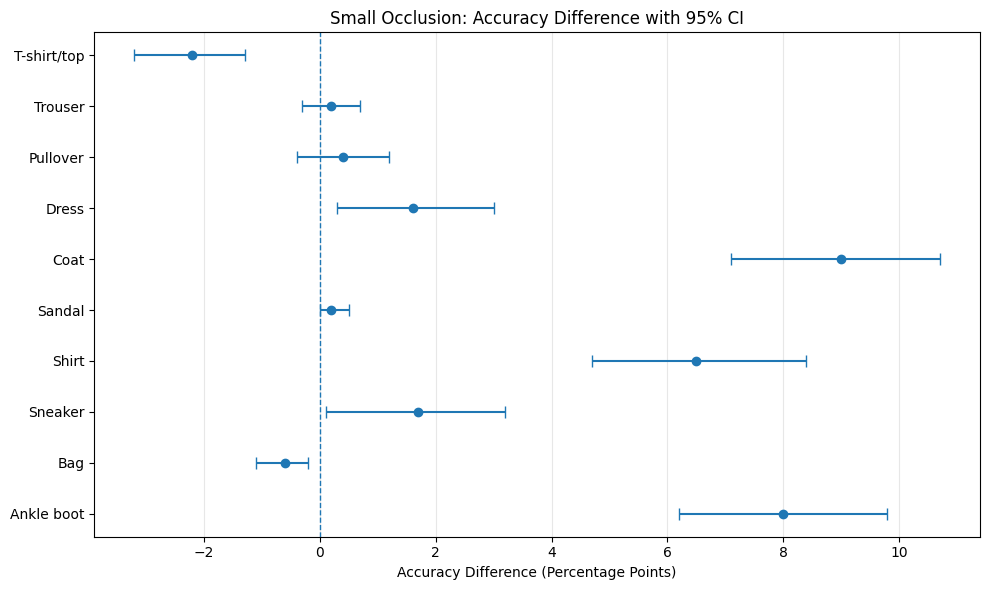

Small figure saved: /content/drive/MyDrive/DLproject1/results/bootstrap_ci_small.png


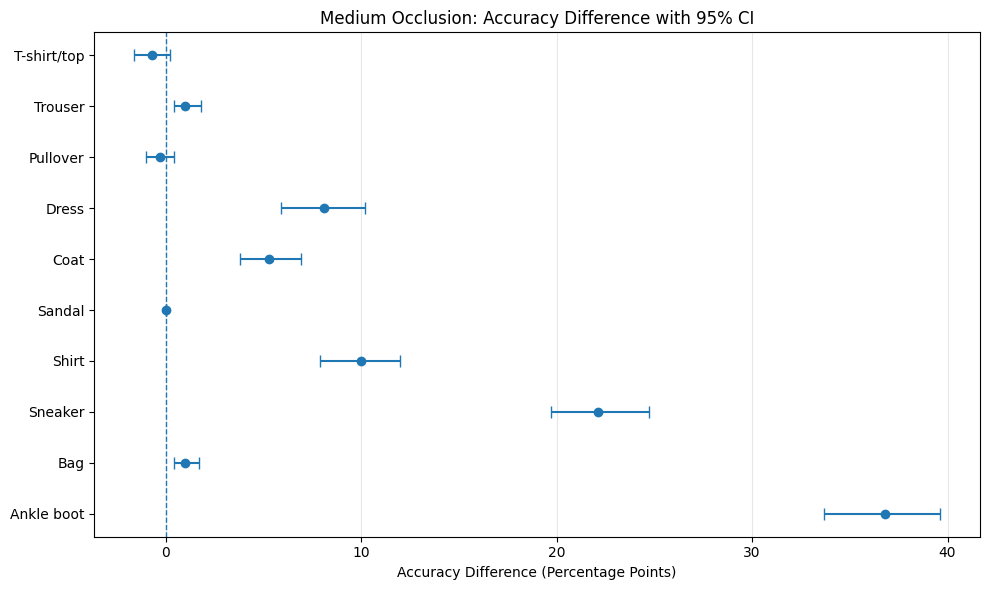

Medium figure saved: /content/drive/MyDrive/DLproject1/results/bootstrap_ci_medium.png


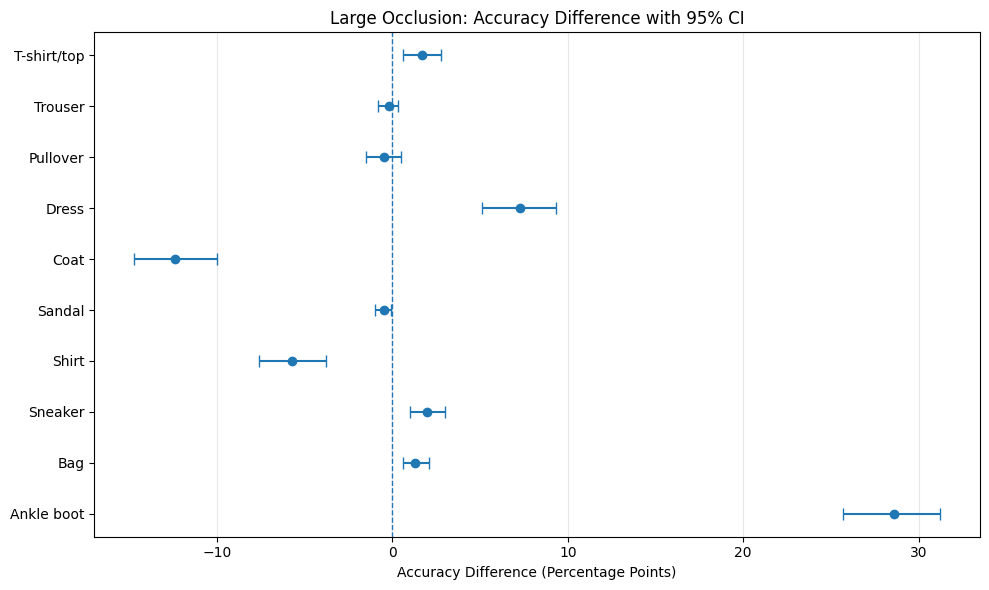

Large figure saved: /content/drive/MyDrive/DLproject1/results/bootstrap_ci_large.png


In [ ]:
# Cell 28: Visualize Bootstrap Confidence Intervals

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load saved bootstrap results
bootstrap_path = os.path.join(
    dataset_path,
    "results",
    "bootstrap_confidence_intervals.csv"
)

bootstrap_results = pd.read_csv(bootstrap_path)

# Create a separate plot for each occlusion size
for size in ["Small", "Medium", "Large"]:

    data = bootstrap_results[
        bootstrap_results["Size"] == size
    ].set_index("Class").reindex(classes)

    differences = data["Accuracy Difference"].to_numpy()
    lower = data["CI Lower"].to_numpy()
    upper = data["CI Upper"].to_numpy()

    # Calculate confidence interval error bars
    errors = np.array([
        differences - lower,
        upper - differences
    ])

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.errorbar(
        differences,
        range(len(classes)),
        xerr=errors,
        fmt="o",
        capsize=4
    )

    # Zero indicates equal accuracy
    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes)
    ax.invert_yaxis()

    ax.set_xlabel("Accuracy Difference (Percentage Points)")
    ax.set_title(
        f"{size} Occlusion: Accuracy Difference with 95% CI"
    )

    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()

    # Save figure to Google Drive
    save_path = os.path.join(
        dataset_path,
        "results",
        f"bootstrap_ci_{size.lower()}.png"
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"{size} figure saved:", save_path)